# 05 — SWISS International Air Lines Agent in LangGraph

**Lernziel.** Du baust Schritt für Schritt einen Agenten als Graph: Er prüft zuerst,
ob eine Frage überhaupt zu ihm gehört, schlägt dann Tarifdaten mit einem Werkzeug
nach, statt zu raten, und liefert seine Antwort in einer festen Struktur. Unterwegs
lernst du State, Knoten, Kanten, strukturierte Ausgabe und Tools kennen.

**Dauer.** Rund 60 Minuten.

**Voraussetzungen.** Notebook 04 gelaufen. Für das Tracing ein LangSmith-Konto —
das richten wir in diesem Notebook ein.

**Empfohlen:** lokal ausführen, zum Beispiel in PyCharm.

---

Wieder am selben Fall: ein Prototyp, der Fragen zu einer Reise mit SWISS beantwortet.
SWISS ist ein reales Unternehmen; dies hier ist eine Übung und kein offizieller Dienst.

## Das Ziel

Am Ende dieses Notebooks steht dieser Graph:

```
                    START
                      │
                  classify
                 ╱        ╲
      nicht zuständig    zuständig
               │             │
            reject        answer ⇄ tools
               │             │
               │          respond
               │             │
               └──── END ────┘
```

| Knoten | Aufgabe |
|---|---|
| `classify` | prüft, ob die Frage zu SWISS gehört, und bestimmt ihr Thema |
| `reject` | lehnt höflich ab, ohne das Modell zu fragen |
| `answer` | das Modell antwortet oder fordert ein Werkzeug an |
| `tools` | führt das Werkzeug `fare_lookup` aus und gibt das Ergebnis zurück an `answer` |
| `respond` | bringt die fertige Antwort in eine feste Struktur |

Wir bauen die Teile der Reihe nach und setzen sie erst in Schritt 8 zusammen. Bis
dahin probieren wir jedes Teil einzeln aus. In den nächsten Wochen kommen weitere
Werkzeuge dazu (Woche 6: MCP, Woche 7: Dokumentensuche) — der Graph bleibt derselbe.

## Setup

Die folgenden Zellen kennt ihr aus Woche 4: Installation, Modell, Schlüssel,
Verbindungstest. Neu dazwischen liegt eine Zelle für das Tracing. Sie steht bewusst
**vor** dem ersten Modellaufruf — warum, steht gleich dort.

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [1]:
LLM_MODEL = "gpt-5.6-luna"
LLM_BASE_URL = "https://litellm.engines.aisl.science/v1"

# Weitere Modelle auf demselben Proxy:
#   "azure_ai/mistral-large-3"

In [2]:
import os
from dotenv import load_dotenv
from getpass import getpass

# load_dotenv liest die .env, überschreibt aber nichts, was schon gesetzt ist.
load_dotenv()

if not os.environ.get("LITELLM_API_KEY"):
    os.environ["LITELLM_API_KEY"] = getpass("LITELLM_API_KEY: ")

### Tracing mit LangSmith einschalten

Ein Graph macht mehrere Aufrufe, und man sieht nur noch das Ergebnis. LangSmith
zeichnet jeden Aufruf auf — inklusive dem, was wirklich an das Modell ging.

**Jetzt ein Konto anlegen:** [smith.langchain.com](https://smith.langchain.com) →
registrieren → *Settings* → *API Keys* → Schlüssel erzeugen und als
`LANGSMITH_API_KEY` in die `.env` schreiben. Gratis, keine Kreditkarte.

Wer das gerade nicht kann, macht trotzdem weiter — das Notebook läuft ohne Tracing.

Die Zelle steht vor dem Verbindungstest, und das ist kein Zufall: LangSmith liest
die Umgebungsvariablen beim **ersten** Modellaufruf und merkt sich das Ergebnis.
Schaltet man das Tracing erst danach ein, bleibt es aus.

In [3]:
if os.environ.get("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "genai_swiss_cw5"
    print("Tracing läuft. Projekt:", os.environ["LANGSMITH_PROJECT"])
else:
    os.environ["LANGSMITH_TRACING"] = "false"
    print("Kein LANGSMITH_API_KEY gefunden — weiter ohne Tracing.")

Tracing läuft. Projekt: genai_swiss_cw5


In [6]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=LLM_MODEL,
    base_url=LLM_BASE_URL,
    api_key=os.environ["LITELLM_API_KEY"],
    temperature=0,
)

print(llm.invoke("Antworte mit einem Wort: bereit?").content)

Bereit


## Schritt 1: Die Prompts

Der System-Prompt legt fest, wer das Modell sein soll und woran es sich hält. Er
steht als Konstante oben im Code und nicht mitten in einer Funktion: So findet man
ihn wieder und kann ihn ändern, ohne den Graphen zu lesen.

Der Prompt ist in drei Abschnitte gegliedert:

- **Fakten:** woher das Wissen kommt und was nicht erfunden werden darf. Er nennt
  schon das Werkzeug `fare_lookup`, das wir in Schritt 4 bauen.
- **Antwortstil:** Anrede, Sprache, Länge. Ohne solche Vorgaben wechselt das Modell
  zwischen «du» und «Sie» und schreibt mal einen Satz, mal eine halbe Seite.
- **Kennzeichnung:** SWISS ist ein reales Unternehmen, der Prototyp darf nicht wie
  ein offizieller Dienst wirken.

Diese Vorgaben sind später auch die Prüfkriterien: In Woche 9 testen wir, ob die
Antworten sie einhalten.

In [7]:
SYSTEM_PROMPT = """Du bist ein Assistent, der Fragen zu Tarifen und Gepäck bei
SWISS International Air Lines beantwortet.

Fakten:
- Schlage Tarifkonditionen und Gebühren immer mit dem Werkzeug fare_lookup nach.
- Steht etwas nicht in den Daten, sage das. Erfinde keine Gepäckregeln,
  Gebühren, Fristen oder Kontaktdaten wie Telefonnummern.
- Fehlt eine Angabe, etwa der Tarif, frage nach, statt zu raten.

Antwortstil:
- Sprich die Person mit «Sie» an und antworte in der Sprache der Frage.
- Höchstens vier Sätze oder eine kurze Liste, keine Überschriften.
- Nenne bei Gebühren immer den Tarif, auf den sie sich beziehen.

Kennzeichnung:
- Du bist ein Prototyp aus einer Lehrveranstaltung der FHNW und kein offizieller
  Dienst von SWISS. Sage das, wenn jemand dich für den offiziellen Kundendienst hält."""

Ein zweiter Prompt ist für die Prüfung am Eingang: Gehört die Frage überhaupt zu
uns? Das ist eine andere Aufgabe als das Antworten, deshalb eine eigene Konstante.

In [8]:
CLASSIFY_PROMPT = """Entscheide, ob eine Frage in den Zuständigkeitsbereich eines
Assistenten für SWISS International Air Lines fällt, und bestimme ihr Thema.

Zuständig: Flüge, Tarife, Gepäck, Buchung, Umbuchung und Erstattung bei SWISS,
ausserdem Fragen an den Assistenten selbst (wer er ist, was er kann).
Nicht zuständig: andere Fluggesellschaften und alles, was nichts mit Fliegen
bei SWISS zu tun hat."""

## Schritt 2: Strukturierte Ausgabe

Fliesstext ist schön zu lesen, aber ein Programm kann damit wenig anfangen. Mit
**strukturierter Ausgabe** bekommt man vom Modell statt eines Textes ein ausgefülltes
Objekt mit festen Feldern. Wir brauchen das zweimal: für die Prüfung am Eingang und
für die Antwort am Ende.

Beschrieben wird die Struktur mit **Pydantic**, einer Bibliothek, die aus
Typ-Angaben eine Prüfung macht. Man beschreibt, wie Daten aussehen sollen, und
Pydantic sorgt dafür, dass sie auch so aussehen — sonst gibt es einen Fehler statt
eines falschen Werts.

- **`BaseModel`** ist die Klasse, von der man erbt. `in_scope: bool` heisst dann
  nicht «hier steht vermutlich etwas Wahres», sondern «hier **muss** `True` oder
  `False` stehen».
- **`Literal[...]`** erlaubt nur die aufgezählten Werte. Das Modell kann kein
  eigenes Thema erfinden.
- **`Field`** beschreibt ein Feld genauer. Die `description` ist kein Kommentar für
  uns, sondern wird als Anweisung an das Modell mitgeschickt.

In [9]:
from typing import Literal
from pydantic import BaseModel, Field


class Classification(BaseModel):
    """Ergebnis der Prüfung am Eingang."""

    reason: str = Field(description="Begründung in einem Satz")
    in_scope: bool = Field(description="True, wenn die Frage in den Zuständigkeitsbereich fällt")
    category: Literal["fare", "baggage", "booking", "refund", "other"] = Field(
        description="Thema: fare = Tarif, baggage = Gepäck, booking = Buchung und Umbuchung, "
                    "refund = Erstattung und Annullierung, other = alles andere")

Die zweite Struktur ist die Antwort, die der Agent am Ende abliefert. Statt eines
Textes gibt es drei Felder, mit denen ein Programm weiterarbeiten kann: In Woche 9
zeigt die Oberfläche sie an, und `needs_human` wird in Woche 8 entscheiden, ob ein
Mensch übernimmt.

Wann ein Mensch übernehmen muss, steht in der `description` von `needs_human` und
nicht im System-Prompt: Dort, wo das Modell das Feld ausfüllt, liest es auch die
Regel dazu.

In [10]:
class AgentResponse(BaseModel):
    """Strukturierte Antwort des Agenten."""

    answer: str = Field(description="Antwort an die Kundin oder den Kunden")
    fare: str | None = Field(description="Tarif, um den es geht, falls einer genannt wird")
    needs_human: bool = Field(
        description="True bei Beschwerden, Entschädigungsforderungen, Notlagen unterwegs "
                    "oder wenn eine Buchung geändert werden muss")

`with_structured_output` verbindet Modell und Schema. Wir probieren den Klassifikator
gleich mit zwei Fragen aus — noch ohne Graph.

In [11]:
from langchain.messages import HumanMessage, SystemMessage

# method="json_schema": das Modell füllt ein JSON-Schema aus.
classifier = llm.with_structured_output(Classification, method="json_schema")

for question in ["Darf ich in Economy Light einen Koffer aufgeben?",
                 "Wie viel Freigepäck hat man bei Lufthansa?"]:
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT),
                                HumanMessage(content=question)])
    print(question)
    print(f"   in_scope={result.in_scope}, category={result.category}")
    print(f"   {result.reason}\n")

Darf ich in Economy Light einen Koffer aufgeben?
   in_scope=True, category=baggage
   Die Frage betrifft die Gepäckbestimmungen des SWISS-Tarifs Economy Light.

Wie viel Freigepäck hat man bei Lufthansa?
   in_scope=False, category=other
   Die Frage betrifft die Gepäckbestimmungen einer anderen Fluggesellschaft und fällt daher nicht in den Zuständigkeitsbereich von SWISS.



`result.in_scope` ist ein echtes `True` oder `False`, kein Text, aus dem man es erst
herauslesen müsste. Damit kann der Graph in Schritt 7 entscheiden, wohin es geht.

**Nicht jedes Modell kann das.** `azure_ai/gpt-oss-120b` aus Woche 4 scheitert hier
über den Proxy: Der Aufruf läuft in eine Zeitüberschreitung. Deshalb steht oben ein
anderes Modell. Was ein Modell kann, steht in keiner Modellliste — man probiert es aus.

## Schritt 3: Der State

Der State ist das Gedächtnis des Graphen während eines Durchlaufs: ein Dictionary,
das von Knoten zu Knoten weitergereicht wird. Jeder Knoten liest daraus und gibt
zurück, was sich ändern soll. Unser State hat fünf Felder, und fast jedes wird von
einem anderen Knoten geschrieben:

| Feld | geschrieben von | Inhalt |
|---|---|---|
| `messages` | allen | der Gesprächsverlauf |
| `in_scope` | `classify` | gehört die Frage zu uns? |
| `category` | `classify` | Thema der Frage |
| `tools_used` | `tools` | welche Werkzeuge aufgerufen wurden |
| `response` | `respond` oder `reject` | die strukturierte Antwort |

Zwei Felder sind mit `operator.add` markiert. Gibt ein Knoten dafür neue Werte
zurück, werden sie **angehängt** — so wächst der Gesprächsverlauf, statt bei jedem
Schritt verloren zu gehen. Bei allen anderen Feldern **ersetzt** ein neuer Wert den
alten.

`tools_used` füllt übrigens unser Code, nicht das Modell. Was dort steht, ist
deshalb verlässlich.

In [17]:
import operator
from typing_extensions import Annotated, TypedDict
from langchain.messages import AnyMessage


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    in_scope: bool
    category: str
    tools_used: Annotated[list[str], operator.add]
    response: AgentResponse

## Schritt 4: Das Werkzeug `fare_lookup`

In Woche 4 hat das Modell Gepäckregeln erfunden, weil es keine Daten hatte. Jetzt
bekommt es ein Werkzeug, mit dem es nachschlagen kann.

Ein Werkzeug ist eine gewöhnliche Python-Funktion mit dem Dekorator `@tool`. Zwei
Dinge daran sind nicht Kosmetik, sondern funktional:

- Die **Typ-Annotation** (`fare: str`) wird in ein Schema übersetzt, das das Modell
  ausfüllt.
- Der **Docstring** ist die Beschreibung, die das Modell zu sehen bekommt. Er
  entscheidet mit darüber, ob das Werkzeug aufgerufen wird. Mehr dazu in Woche 6.

Die Daten stehen als Tabelle im Code — bewusst keine Datenbank, keine API.

> **Vereinfachung.** Diese Tabelle enthält **Beispieldaten für den Unterricht**, keine
> echten Tarifbedingungen von SWISS. Es geht um den Mechanismus, nicht um die Werte.
> Für den eigenen Use-Case setzt man hier die richtigen Daten ein.

In [13]:
FARES = {
    "economy light":   {"carry_on": "1 Stück, 8 kg", "checked_baggage": "kein Freigepäck",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "nicht umbuchbar",
                        "seat_selection": "ab CHF 15"},
    "economy classic": {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "CHF 80",
                        "seat_selection": "ab CHF 15"},
    "economy flex":    {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "kostenlos",
                        "seat_selection": "inklusive"},
}

Findet die Funktion einen Tarif nicht, gibt sie keinen Fehler, sondern einen Satz
zurück. Der landet beim Modell, und das Modell kann damit umgehen — etwa nachfragen.

In [14]:
from langchain.tools import tool


@tool
def fare_lookup(fare: str) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex.
    """
    data = FARES.get(fare.strip().lower())
    if data is None:
        return f"Tarif '{fare}' ist nicht in der Tabelle. Bekannt sind: {', '.join(FARES)}."
    return ", ".join(f"{k}: {v}" for k, v in data.items())


print(fare_lookup.invoke({"fare": "Economy Light"}))

carry_on: 1 Stück, 8 kg, checked_baggage: kein Freigepäck, extra_bag_fee: CHF 60, rebooking_fee: nicht umbuchbar, seat_selection: ab CHF 15


## Schritt 5: Das Werkzeug an das Modell binden

`bind_tools` schickt die Beschreibung der Werkzeuge bei jedem Aufruf mit. Das Modell
bekommt damit die Möglichkeit zu sagen «ruf bitte `fare_lookup` mit diesem Wert
auf» — **ausführen kann es das Werkzeug nicht**. Das muss unser Code tun.

Man sieht das an der Antwort: `content` ist leer, dafür steht in `tool_calls` ein
Auftrag.

In [15]:
tools = [fare_lookup]
tools_by_name = {t.name: t for t in tools}

llm_with_tools = llm.bind_tools(tools)

response = llm_with_tools.invoke("Was kostet eine Umbuchung in Economy Classic?")
print("content:   ", repr(response.content))
print("tool_calls:", response.tool_calls)

content:    ''
tool_calls: [{'name': 'fare_lookup', 'args': {'fare': 'Economy Classic'}, 'id': 'call_PeSDXn1pBG2GJDIloGebfyBf', 'type': 'tool_call'}]


## Schritt 6: Die Knoten

Ein Knoten ist eine Funktion: State rein, Änderung am State raus. Er gibt nur die
Felder zurück, die er ändert — den Rest lässt LangGraph, wie er ist.

Zuerst die beiden Knoten am Eingang. `classify` benutzt den Klassifikator aus
Schritt 2 und schreibt `in_scope` und `category`. `reject` füllt die Antwort direkt
im Code — **ein Knoten muss kein Modell aufrufen**. Das ist schneller, kostet
nichts und antwortet immer gleich.

> **Vereinfachung.** Der Ablehnungstext ist immer deutsch, auch wenn die Frage auf
> Englisch kam. Der Antwortstil aus Schritt 1 gilt nur für Antworten des Modells.

In [18]:
from langchain.messages import AIMessage


def classify(state: AgentState):
    """Prüft, ob die letzte Frage zu SWISS gehört, und bestimmt ihr Thema."""
    question = state["messages"][-1]
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT), question])
    return {"in_scope": result.in_scope, "category": result.category}


def reject(state: AgentState):
    """Lehnt höflich ab. Fester Text, kein Modellaufruf."""
    text = ("Dabei kann ich leider nicht helfen. Ich beantworte nur Fragen zu Flügen, "
            "Tarifen und Gepäck bei SWISS.")
    return {"messages": [AIMessage(content=text)],
            "response": AgentResponse(answer=text, fare=None, needs_human=False)}

Dann der Knoten, der antwortet. Er stellt den System-Prompt vor den Verlauf und
ruft das Modell **mit** Werkzeugen auf. Zurück kommt entweder eine Antwort als Text
oder ein Auftrag, ein Werkzeug aufzurufen.

In [19]:
def answer(state: AgentState):
    """Das Modell antwortet oder fordert ein Werkzeug an."""
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    return {"messages": [llm_with_tools.invoke(messages)]}

Der Knoten, der die Aufträge ausführt. Er nimmt die letzte Nachricht, führt jeden
darin angeforderten Werkzeugaufruf aus und legt das Ergebnis als `ToolMessage` in den
Verlauf. Die `tool_call_id` sagt dem Modell, welches Ergebnis zu welchem Auftrag
gehört. Nebenbei trägt er die Namen der Werkzeuge in `tools_used` ein.

LangGraph hat für das Ausführen auch einen fertigen Baustein (`ToolNode`). Wir
schreiben ihn hier selbst, weil man so sieht, dass dahinter nur eine Schleife steckt.

In [20]:
from langchain.messages import ToolMessage


def call_tools(state: AgentState):
    """Führt die Werkzeuge aus, die das Modell angefordert hat."""
    tool_calls = state["messages"][-1].tool_calls
    results = []
    for tool_call in tool_calls:
        result = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
        results.append(ToolMessage(content=str(result), tool_call_id=tool_call["id"]))
    return {"messages": results, "tools_used": [c["name"] for c in tool_calls]}

Zum Schluss `respond`: Er nimmt das fertige Gespräch und lässt das Modell die
Antwort in die Struktur `AgentResponse` bringen. Das kostet einen Modellaufruf mehr,
dafür ist das Ergebnis immer gleich aufgebaut.

Die Anweisung am Ende hängen wir nur für diesen einen Aufruf an, im State landet sie
nicht. «Unverändert» steht bewusst darin: Sonst formuliert das Modell die Antwort neu
und schmückt sie dabei gern noch einmal aus. Sie ist nötig, weil manche Modelle — zum Beispiel `azure_ai/mistral-large-3` — keine
Anfrage annehmen, deren letzte Nachricht vom Modell selbst stammt. Mit der Anweisung
funktioniert der Knoten mit jedem Modell.

In [21]:
responder = llm.with_structured_output(AgentResponse, method="json_schema")


def respond(state: AgentState):
    """Bringt die fertige Antwort in die Struktur AgentResponse."""
    messages = ([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
                + [HumanMessage(content="Übernimm deine letzte Antwort unverändert in das vorgegebene Format.")])
    return {"response": responder.invoke(messages)}

## Schritt 7: Die Kanten

Eine gewöhnliche Kante sagt: Nach Knoten A kommt immer Knoten B. Eine **bedingte
Kante** fragt eine Funktion, wohin es weitergeht. Die Funktion liest den State und
gibt den Namen des nächsten Knotens zurück.

Wir brauchen zwei davon, und sie sind gleich gebaut:

- Nach `classify`: Ist die Frage zuständig? Dann `answer`, sonst `reject`.
- Nach `answer`: Hat das Modell ein Werkzeug angefordert? Dann `tools`, sonst
  `respond`.

Von `tools` führt eine gewöhnliche Kante **zurück** zu `answer`. Diese Schleife ist
der Kern eines Agenten: Das Modell darf so lange Werkzeuge benutzen, bis es genug
weiss.

In [22]:
def route_after_classify(state: AgentState):
    """Zuständig: weiter zu answer. Sonst: reject."""
    if state["in_scope"]:
        return "answer"
    return "reject"


def route_after_answer(state: AgentState):
    """Offene Werkzeugaufrufe: weiter zu tools. Sonst: respond."""
    if state["messages"][-1].tool_calls:
        return "tools"
    return "respond"

## Schritt 8: Den Graphen zusammenbauen

Jetzt kommen alle Teile zusammen. `build_graph()` registriert die Knoten unter ihrem
Namen, verbindet sie mit Kanten und kompiliert den Graphen. Die Funktion heisst in
allen Notebooks gleich, damit man den Block weiterverwenden kann.

Die Liste am Ende von `add_conditional_edges` nennt die möglichen Ziele. Ohne sie
könnte LangGraph den Graphen nicht zeichnen.

In [23]:
from langgraph.graph import StateGraph, START, END


def build_graph():
    builder = StateGraph(AgentState)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools)
    builder.add_node("respond", respond)

    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile()


graph = build_graph()

Der kompilierte Graph kann sich selbst zeichnen. Vergleiche das Bild mit der Skizze
ganz oben: Gestrichelte Pfeile sind bedingte Kanten.

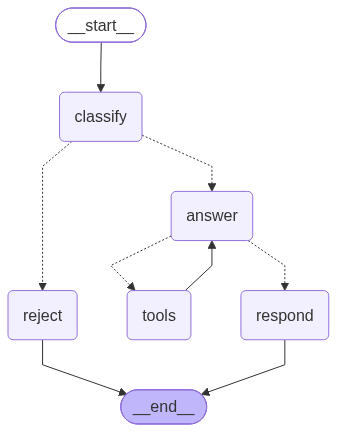

In [24]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

## Schritt 9: Ausprobieren

Eine kleine Einstiegsfunktion: Frage rein, Antworttext raus. `ask` heisst sie in
allen Notebooks gleich.

Zuerst die Frage aus Woche 4. Damals hat das blanke Modell Gepäckregeln erfunden.

In [25]:
def ask(question):
    result = graph.invoke({"messages": [HumanMessage(content=question)]}, debug=True)
    return result["response"].answer


print(ask("Was ist der Unterschied zwischen Economy Light und Economy Classic bei SWISS?"))

[values] {'messages': [HumanMessage(content='Was ist der Unterschied zwischen Economy Light und Economy Classic bei SWISS?', additional_kwargs={}, response_metadata={})], 'tools_used': []}
[updates] {'classify': {'in_scope': True, 'category': 'fare'}}
[values] {'messages': [HumanMessage(content='Was ist der Unterschied zwischen Economy Light und Economy Classic bei SWISS?', additional_kwargs={}, response_metadata={})], 'in_scope': True, 'category': 'fare', 'tools_used': []}
[updates] {'answer': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 66, 'prompt_tokens': 394, 'total_tokens': 460, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 7, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'cache_creation_tokens': 0}, 'l

Die Werte stammen jetzt aus der Tabelle. Ändere einen Wert in `FARES`, führe die
Zellen ab Schritt 4 neu aus und frag erneut — die Antwort ändert sich mit.

**Trotzdem genau lesen.** Steht in der Antwort etwas, das nicht in der Tabelle
steht? Modelle schmücken gern aus, auch wenn sie nachgeschlagen haben. Ein Werkzeug
verringert das Erfinden, verhindert es aber nicht. Wie man das systematisch prüft,
ist Thema in Woche 9.

Nun eine Frage, für die der Agent nicht zuständig ist, und eine an den Agenten selbst:

In [26]:
print(ask("Wie viel Freigepäck hat man bei Lufthansa?"))

[values] {'messages': [HumanMessage(content='Wie viel Freigepäck hat man bei Lufthansa?', additional_kwargs={}, response_metadata={})], 'tools_used': []}
[updates] {'classify': {'in_scope': False, 'category': 'baggage'}}
[values] {'messages': [HumanMessage(content='Wie viel Freigepäck hat man bei Lufthansa?', additional_kwargs={}, response_metadata={})], 'in_scope': False, 'category': 'baggage', 'tools_used': []}
[updates] {'reject': {'messages': [AIMessage(content='Dabei kann ich leider nicht helfen. Ich beantworte nur Fragen zu Flügen, Tarifen und Gepäck bei SWISS.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])], 'response': AgentResponse(answer='Dabei kann ich leider nicht helfen. Ich beantworte nur Fragen zu Flügen, Tarifen und Gepäck bei SWISS.', fare=None, needs_human=False)}}
[values] {'messages': [HumanMessage(content='Wie viel Freigepäck hat man bei Lufthansa?', additional_kwargs={}, response_metadata={}), AIMessage(content='Dabei kann ich 

In [27]:
print(ask("Bist du der offizielle Kundendienst von SWISS?"))

[values] {'messages': [HumanMessage(content='Bist du der offizielle Kundendienst von SWISS?', additional_kwargs={}, response_metadata={})], 'tools_used': []}
[updates] {'classify': {'in_scope': True, 'category': 'other'}}
[values] {'messages': [HumanMessage(content='Bist du der offizielle Kundendienst von SWISS?', additional_kwargs={}, response_metadata={})], 'in_scope': True, 'category': 'other', 'tools_used': []}
[updates] {'answer': {'messages': [AIMessage(content='Nein. Ich bin ein Prototyp aus einer Lehrveranstaltung der FHNW und kein offizieller Kundendienst von SWISS.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 392, 'total_tokens': 421, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'tex

Und zwei Fragen zum Antwortstil aus Schritt 1: eine ohne Tarif — der Agent soll
nachfragen, statt zu raten — und eine auf Englisch.

In [25]:
print(ask("Kann ich meinen Flug umbuchen?"))

[values] {'messages': [HumanMessage(content='Kann ich meinen Flug umbuchen?', additional_kwargs={}, response_metadata={})], 'tools_used': []}
[updates] {'classify': {'in_scope': True, 'category': 'booking'}}
[values] {'messages': [HumanMessage(content='Kann ich meinen Flug umbuchen?', additional_kwargs={}, response_metadata={})], 'in_scope': True, 'category': 'booking', 'tools_used': []}
[updates] {'answer': {'messages': [AIMessage(content='Das hängt von Ihrem gebuchten Tarif ab. Welchen Tarif haben Sie gebucht – Economy Light, Economy Classic oder Economy Flex?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 387, 'total_tokens': 442, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 20, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': N

In [26]:
print(ask("How much does an extra bag cost in Economy Light?"))

[values] {'messages': [HumanMessage(content='How much does an extra bag cost in Economy Light?', additional_kwargs={}, response_metadata={})], 'tools_used': []}
[updates] {'classify': {'in_scope': True, 'category': 'baggage'}}
[values] {'messages': [HumanMessage(content='How much does an extra bag cost in Economy Light?', additional_kwargs={}, response_metadata={})], 'in_scope': True, 'category': 'baggage', 'tools_used': []}
[updates] {'answer': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 391, 'total_tokens': 411, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'cache_creation_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 8, 'engine_t

### Was im State steht

`ask` zeigt nur den Antworttext. Der ganze State zeigt mehr: das Thema, die benutzten
Werkzeuge und die strukturierte Antwort. Die zweite Frage kann der Agent nicht selbst
lösen — achte auf `needs_human`.

In [27]:
for question in ["Was kostet ein zusätzlicher Koffer in Economy Light?",
                 "Mein Flug ab Bangkok wurde gestrichen und ich sitze fest. Was nun?"]:
    result = graph.invoke({"messages": [HumanMessage(content=question)]})
    print(question)
    print("   category:   ", result["category"])
    print("   tools_used: ", result["tools_used"])
    print("   fare:       ", result["response"].fare)
    print("   needs_human:", result["response"].needs_human)
    print("   answer:     ", result["response"].answer, "\n")

Was kostet ein zusätzlicher Koffer in Economy Light?
   category:    baggage
   tools_used:  ['fare_lookup']
   fare:        Economy Light
   needs_human: False
   answer:      Ein zusätzlicher Koffer kostet im Tarif **Economy Light CHF 60**. 

Mein Flug ab Bangkok wurde gestrichen und ich sitze fest. Was nun?
   category:    refund
   tools_used:  []
   fare:        None
   needs_human: True
   answer:      Wenn Ihr SWISS-Flug ab Bangkok gestrichen wurde, prüfen Sie zuerst die SWISS-App bzw. Ihre E-Mails auf eine automatische Umbuchung und wenden Sie sich zusätzlich an den SWISS-Schalter am Flughafen. Lassen Sie sich eine Umbuchung oder Erstattung bestätigen; buchen Sie keinen Ersatzflug, bevor die Kostenübernahme geklärt ist, und bewahren Sie Belege für notwendige Ausgaben auf. Fragen Sie am Schalter auch nach Unterstützung wie Unterkunft oder Verpflegung, sofern diese in Ihrer Situation vorgesehen ist. 



### Zuschauen, wer was schreibt

`graph.invoke` liefert erst am Ende den fertigen State. `graph.stream` mit
`stream_mode="updates"` liefert dasselbe **Schritt für Schritt**: Nach jedem Knoten
kommt genau das zurück, was dieser Knoten geändert hat. So sieht man den Weg durch
den Graphen und welcher Knoten welches Feld füllt.

In [28]:
question = "Was kostet eine Umbuchung in Economy Classic?"

for update in graph.stream({"messages": [HumanMessage(content=question)]},
                           stream_mode="updates"):
    for node, changes in update.items():
        print(f"{node:9} schreibt {list(changes)}")

classify  schreibt ['in_scope', 'category']
answer    schreibt ['messages']
tools     schreibt ['messages', 'tools_used']
answer    schreibt ['messages']
respond   schreibt ['response']


`answer` kommt zweimal vor: einmal mit dem Auftrag an das Werkzeug, einmal mit der
Antwort. Dazwischen liegt `tools` — das ist die Schleife aus Schritt 7.

## Schritt 10: Den Trace anschauen

Wer ein LangSmith-Konto hat, öffnet jetzt [smith.langchain.com](https://smith.langchain.com),
wählt das Projekt `genai_swiss_cw5` und klickt die letzten Läufe an.

Der Trace zeigt denselben Weg wie `stream_mode="updates"`, nur ausführlicher: Jeder
Knoten ist ein eigener Schritt, und darin stecken die Modellaufrufe.

- Bei einer Frage mit Werkzeug siehst du `classify → answer → tools → answer →
  respond`: vier Modellaufrufe für eine Antwort.
- Bei der Frage zu Lufthansa siehst du `classify → reject`: ein einziger
  Modellaufruf, die Ablehnung selbst kostet nichts.

Klick einen `answer`-Schritt an. Dort steht, was wirklich an das Modell ging: der
System-Prompt, die Nachrichten in ihrer Reihenfolge, die Beschreibung des Werkzeugs,
die Antwort, die Dauer und die Anzahl Token. Die Frage «was schickt der Graph
eigentlich?» ist damit ein für alle Mal beantwortet.

## Aufgaben bis zur nächsten Woche:

- **Zuständigkeit:** Schreib `CLASSIFY_PROMPT` für euren eigenen Use-Case um. Teste
  Grenzfälle — bei SWISS etwa «Ich fliege mit Edelweiss, wie viel Gepäck darf ich
  mitnehmen?». Was soll passieren, und was passiert?
- **Eigenes Werkzeug:** Schreib ein zweites Werkzeug mit einer eigenen kleinen
  Tabelle und häng es in `tools` ein. Am Graphen ändert sich nichts — aber die
  Zellen ab Schritt 5 müssen neu laufen. Taucht es in `tools_used` auf?
- **Antwortstil:** Schreib den Abschnitt «Antwortstil» in `SYSTEM_PROMPT` für euren
  Use-Case. Welche Vorgaben braucht ihr, damit die Antworten einheitlich sind?
- **Schema:** Ergänze in `AgentResponse` ein Feld, das ihr für euren Use-Case
  braucht, zum Beispiel `follow_up_question: str | None`. Was passiert, wenn du die
  `description` weglässt?
- **Ablehnung:** Lass `reject` das Modell fragen, statt einen festen Text zu
  liefern. Was ändert sich im Trace?
- **Trace:** Wie viele Token kostet eine Frage mit Werkzeug, wie viele eine
  abgelehnte?

## Baustein zum Mitnehmen

In [29]:
import operator, os
from typing import Literal
from typing_extensions import Annotated, TypedDict
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage, ToolMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

load_dotenv()

LLM_MODEL = "gpt-5.6-luna"
LLM_BASE_URL = "https://litellm.engines.aisl.science/v1"

llm = ChatOpenAI(
    model=LLM_MODEL,
    base_url=LLM_BASE_URL,
    api_key=os.environ["LITELLM_API_KEY"],
    temperature=0,
)

SYSTEM_PROMPT = """Du beantwortest Fragen zu Tarifen und Gepäck bei SWISS.
Fakten: Schlage Konditionen und Gebühren mit fare_lookup nach. Erfinde nichts, auch keine Kontaktdaten.
Fehlt eine Angabe, frage nach.
Antwortstil: Sprich die Person mit «Sie» an, antworte in der Sprache der Frage, höchstens vier Sätze.
Kennzeichnung: Du bist ein Prototyp aus einer Lehrveranstaltung, kein offizieller Dienst von SWISS."""

CLASSIFY_PROMPT = """Entscheide, ob eine Frage zu einem Assistenten für SWISS gehört, und bestimme ihr Thema.
Zuständig: Flüge, Tarife, Gepäck, Buchung, Umbuchung, Erstattung bei SWISS, Fragen an den Assistenten.
Nicht zuständig: andere Fluggesellschaften und alles andere."""

FARES = {
    "economy light":   {"carry_on": "1 Stück, 8 kg", "checked_baggage": "kein Freigepäck",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "nicht umbuchbar",
                        "seat_selection": "ab CHF 15"},
    "economy classic": {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "CHF 80",
                        "seat_selection": "ab CHF 15"},
    "economy flex":    {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "kostenlos",
                        "seat_selection": "inklusive"},
}


@tool
def fare_lookup(fare: str) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex.
    """
    data = FARES.get(fare.strip().lower())
    if data is None:
        return f"Tarif '{fare}' ist nicht in der Tabelle. Bekannt sind: {', '.join(FARES)}."
    return ", ".join(f"{k}: {v}" for k, v in data.items())


tools = [fare_lookup]
tools_by_name = {t.name: t for t in tools}
llm_with_tools = llm.bind_tools(tools)


class Classification(BaseModel):
    reason: str = Field(description="Begründung in einem Satz")
    in_scope: bool = Field(description="True, wenn die Frage in den Zuständigkeitsbereich fällt")
    category: Literal["fare", "baggage", "booking", "refund", "other"] = Field(description="Thema der Frage")


class AgentResponse(BaseModel):
    answer: str = Field(description="Antwort an die Kundin oder den Kunden")
    fare: str | None = Field(description="Tarif, um den es geht, falls einer genannt wird")
    needs_human: bool = Field(description="True bei Beschwerden, Entschädigungsforderungen, Notlagen unterwegs "
                                          "oder wenn eine Buchung geändert werden muss")


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    in_scope: bool
    category: str
    tools_used: Annotated[list[str], operator.add]
    response: AgentResponse


classifier = llm.with_structured_output(Classification, method="json_schema")
responder = llm.with_structured_output(AgentResponse, method="json_schema")


def classify(state: AgentState):
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT), state["messages"][-1]])
    return {"in_scope": result.in_scope, "category": result.category}


def reject(state: AgentState):
    text = "Dabei kann ich leider nicht helfen. Ich beantworte nur Fragen zu SWISS."
    return {"messages": [AIMessage(content=text)],
            "response": AgentResponse(answer=text, fare=None, needs_human=False)}


def answer(state: AgentState):
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"])]}


def call_tools(state: AgentState):
    tool_calls = state["messages"][-1].tool_calls
    results = []
    for tool_call in tool_calls:
        result = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
        results.append(ToolMessage(content=str(result), tool_call_id=tool_call["id"]))
    return {"messages": results, "tools_used": [c["name"] for c in tool_calls]}


def respond(state: AgentState):
    messages = ([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
                + [HumanMessage(content="Übernimm deine letzte Antwort unverändert in das vorgegebene Format.")])
    return {"response": responder.invoke(messages)}


def route_after_classify(state: AgentState):
    return "answer" if state["in_scope"] else "reject"


def route_after_answer(state: AgentState):
    return "tools" if state["messages"][-1].tool_calls else "respond"


def build_graph():
    builder = StateGraph(AgentState)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools)
    builder.add_node("respond", respond)
    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile()


graph = build_graph()


def ask(question):
    return graph.invoke({"messages": [HumanMessage(content=question)]})["response"].answer